# Crime in Los Angeles, 2020–2023: Patterns, Statistics and Arrest Prediction

**A complete data-analytics life-cycle project** on the LAPD *Crime Data from 2020 to Present* open-data set (about 1 million police reports).

| | |
|---|---|
| **Data source** | City of Los Angeles Open Data portal (data.lacity.org) – *Crime Data from 2020 to Present*, published by the Los Angeles Police Department (LAPD) |
| **Unit of analysis** | One police crime report (one row = one report) |
| **Tools** | Python · pandas · SciPy · scikit-learn · XGBoost · TabPFN (transformer) · matplotlib |

### How this notebook follows the Data Analytics Life Cycle

| # | Stage | What happens here |
|---|---|---|
| 1 | Business / problem understanding | Questions, stakeholders, success criteria |
| 2 | Data collection / acquisition | Source, collection process, data dictionary |
| 3 | Data understanding | Structure, missing values, quality problems found |
| 4 | Cleaning & pre-processing | Every fix, with row counts |
| 5 | Transformation & integration | Feature engineering, crime grouping, lookup tables |
| 6 | Exploratory data analysis | Time, place, crime type, victims, outcomes |
| 7 | Statistical analysis | Hypothesis tests **with effect sizes** |
| 8 | Pattern discovery | Modus-operandi (MO) clusters: TF-IDF + SVD + K-Means |
| 9 | Modelling | Logistic Regression vs XGBoost vs **TabPFN (transformer)** |
| 10 | Evaluation | ROC / PR curves, confusion matrix, confidence intervals |
| 11 | Interpretation | What drives arrests (feature contributions) |
| 12 | Communication | Insights, recommendations, limitations |

> **How to run:** see `README.md`. The first run builds a cleaned copy of the data (about 1–2 minutes).

## 0 · Setup

In [1]:
import os, sys, json, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# --- project paths: works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cleaning, crime_groups, mo_patterns, modeling
import stats_utils as su
import viz_style as vs

vs.set_style()
DIVERGING = LinearSegmentedColormap.from_list("div", [vs.BLUE, "#f4f4f2", vs.ORANGE])
TABLES = ROOT / "outputs" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

# --- configuration -------------------------------------------------------------------
SEED = 42
RUN_TABPFN = os.environ.get("NO_TABPFN") != "1"   # set False to skip the transformer model (e.g. no PyTorch)
TABPFN_N_TRAIN = 3000    # labelled rows given to TabPFN as context (CPU-friendly)
TABPFN_N_TEST = 1500     # rows used to compare TabPFN with the other models
KEY = {}                 # key numbers collected for the final summary / presentation

def md_(text):
    display(Markdown(text))

print("Project root:", ROOT)

Project root: C:\Users\ahmed\AppData\Roaming\Claude\scratch-workspaces\9f16af71-7618-481e-b7ef-6ffee8b7e013\21271b52-3490-4284-8e3c-ef340a1e2caa\scratch-2026-11-21-ab84ed\la_crime_analytics


---
## 1 · Business / problem understanding

**Context.** Los Angeles is the second-largest US city. The LAPD records every reported crime, but a report is only the *start* of the story: whether anything happens next (an arrest, a closed case, or an investigation that just continues) varies enormously.

**Who would use this analysis?**
* **Police command staff** – where and when to allocate patrol and detective time.
* **City officials / public-safety planners** – which crime types are growing and which are rarely resolved.
* **Community groups and residents** – an evidence-based picture of crime in their area.

**Analytical questions**

| # | Question | Stage that answers it |
|---|---|---|
| Q1 | How did the volume and mix of reported crime change from 2020 to 2023? | 6, 7 |
| Q2 | *When* and *where* does crime concentrate? | 6, 7 |
| Q3 | Who are the victims, and does that differ by crime type? | 6 |
| Q4 | Are there distinct **modus-operandi (MO) patterns** hiding in the MO codes? | 8 |
| Q5 | What share of reports end in an **arrest**, and which factors are associated with it? | 6, 7, 11 |
| Q6 | Can we **predict** at report time whether a case will end in an arrest, and which model does it best? | 9, 10 |

**Success criteria.** (1) Every stage of the life cycle is documented and reproducible; (2) findings are backed by statistical tests with effect sizes, not just p-values; (3) the prediction model beats a simple baseline on held-out data, evaluated with metrics that suit a rare outcome (≈9 % arrests).

---
## 2 · Data collection / acquisition

* **Source:** LAPD, published on the City of Los Angeles open-data portal as *Crime Data from 2020 to Present* (dataset id `2nrs-mtv8`, https://data.lacity.org). It is an official government source, not a convenience / competition data set.
* **How it was collected (as documented by the publisher):** the data are transcribed from original police crime reports. Because of the manual transcription there can be inaccuracies; unknown locations are recorded as (0°, 0°); street addresses are rounded to the nearest hundred block to protect privacy.
* **How we obtained it:** exported from the portal as a CSV (`data/lapd_crime_2020_present.csv`, ≈ 300 MB, 28 columns). The file is used unmodified; every change is made in code (stage 4) so the work is reproducible.

### Data dictionary (raw attributes)

In [2]:
dictionary = pd.DataFrame([
 ("DR_NO", "Division of Records number – unique report id"),
 ("Date Rptd", "Date the crime was reported"),
 ("DATE OCC", "Date the crime occurred"),
 ("TIME OCC", "Time of occurrence, 24-hour clock (HHMM)"),
 ("AREA / AREA NAME", "One of the 21 LAPD geographic divisions (number / name)"),
 ("Rpt Dist No", "Four-digit reporting district inside a division"),
 ("Part 1-2", "FBI classification: Part 1 = serious (violent/major property), Part 2 = other"),
 ("Crm Cd / Crm Cd Desc", "Primary crime code and its description"),
 ("Mocodes", "Modus-operandi codes: space-separated activities associated with the suspect"),
 ("Vict Age / Vict Sex / Vict Descent", "Victim age, sex (M/F/X) and descent code"),
 ("Premis Cd / Premis Desc", "Type of location (street, apartment, parking lot, ...)"),
 ("Weapon Used Cd / Weapon Desc", "Weapon recorded, if any"),
 ("Status / Status Desc", "Case outcome: Invest Cont, Adult Arrest, Adult Other, Juv Arrest, Juv Other"),
 ("Crm Cd 1-4", "Up to four crime codes per report (1 = most serious)"),
 ("LOCATION / Cross Street", "Street address (rounded to the hundred block) and cross street"),
 ("LAT / LON", "Latitude / longitude of the incident"),
], columns=["Attribute", "Meaning"])
display(dictionary.style.hide(axis="index"))

Attribute,Meaning
DR_NO,Division of Records number – unique report id
Date Rptd,Date the crime was reported
DATE OCC,Date the crime occurred
TIME OCC,"Time of occurrence, 24-hour clock (HHMM)"
AREA / AREA NAME,One of the 21 LAPD geographic divisions (number / name)
Rpt Dist No,Four-digit reporting district inside a division
Part 1-2,"FBI classification: Part 1 = serious (violent/major property), Part 2 = other"
Crm Cd / Crm Cd Desc,Primary crime code and its description
Mocodes,Modus-operandi codes: space-separated activities associated with the suspect
Vict Age / Vict Sex / Vict Descent,"Victim age, sex (M/F/X) and descent code"


---
## 3 · Data understanding

First look at the **raw** file – structure, missing values and data-quality problems – *before* changing anything. The file is read in chunks so this works on a laptop with limited memory.

In [3]:
t0 = time.time()
prof = cleaning.profile_raw()          # chunked pass over the untouched CSV (about 1 minute)
print(f"{prof['rows']:,} rows x {prof['cols']} columns  (profiled in {time.time() - t0:.0f}s)")
display(prof["head"].T.rename(columns=lambda c: f"row {c + 1}"))
KEY["raw_rows"] = int(prof["rows"])
KEY["missing_pct"] = prof["null_pct"][prof["null_pct"] > 1].round(1).to_dict()

1,004,894 rows x 28 columns  (profiled in 6s)


,row 1,row 2,row 3
DR_NO,211507896,201516622,240913563
Date Rptd,2021 Apr 11 12:00:00 AM,2020 Oct 21 12:00:00 AM,2024 Dec 10 12:00:00 AM
DATE OCC,2020 Nov 07 12:00:00 AM,2020 Oct 18 12:00:00 AM,2020 Oct 30 12:00:00 AM
TIME OCC,0845,1845,1240
AREA,15,15,09
AREA NAME,N Hollywood,N Hollywood,Van Nuys
Rpt Dist No,1502,1521,0933
Part 1-2,2,1,2
Crm Cd,354,230,354
Crm Cd Desc,THEFT OF IDENTITY,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",THEFT OF IDENTITY


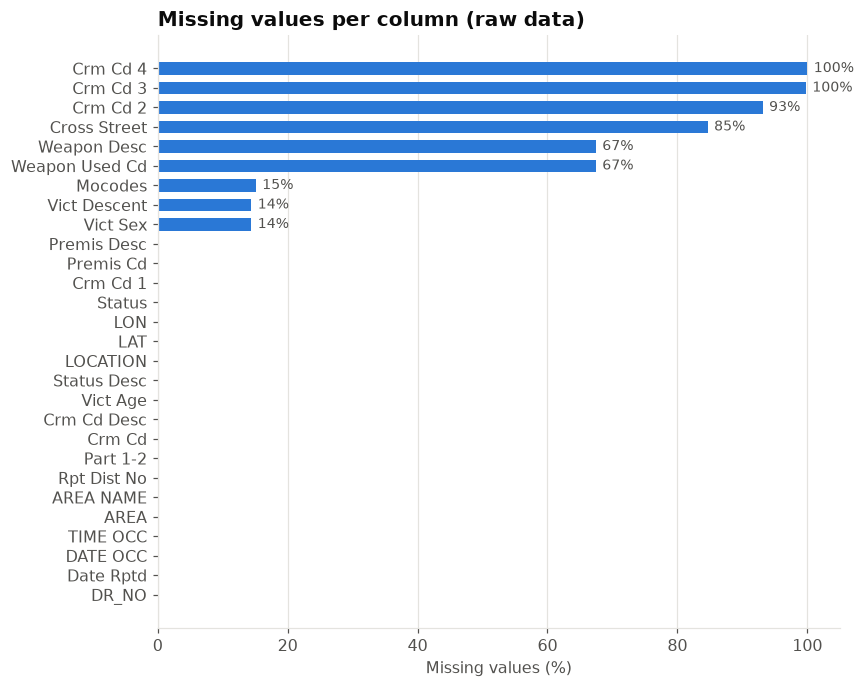

In [4]:
miss = prof["null_pct"].sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(miss.index, miss.values, color=vs.BLUE, height=0.65)
ax.set_xlabel("Missing values (%)")
ax.set_title("Missing values per column (raw data)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(miss.values):
    if v > 1:
        ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=vs.INK_2)
vs.savefig(fig, "03_missing_values"); plt.show()

Missing values alone do not show the whole picture – several columns *look* complete but hide placeholders (age `0`, coordinates `0,0`, sex `X`). Let us look for those.

In [5]:
issues = pd.DataFrame(prof["issues"], columns=["Data-quality issue", "Rows"])
issues["Share of rows"] = (issues["Rows"] / prof["rows"] * 100).map("{:.1f}%".format)
issues["Rows"] = issues["Rows"].map("{:,}".format)
display(issues.style.hide(axis="index"))

Data-quality issue,Rows,Share of rows
Victim age is 0 or negative (not a real age),"269,315",26.8%
Victim age above 100,1,0.0%
"Victim sex is not M or F (blank, X, H, '-')","242,499",24.1%
"Coordinates recorded as 0,0","2,240",0.2%
No Mocodes recorded,"151,598",15.1%
No weapon recorded,"677,678",67.4%
Duplicate report numbers,0,0.0%


**The most important discovery: 2024 is incomplete.** Plotting volume and arrest rate over time shows a structural break at the start of 2024.

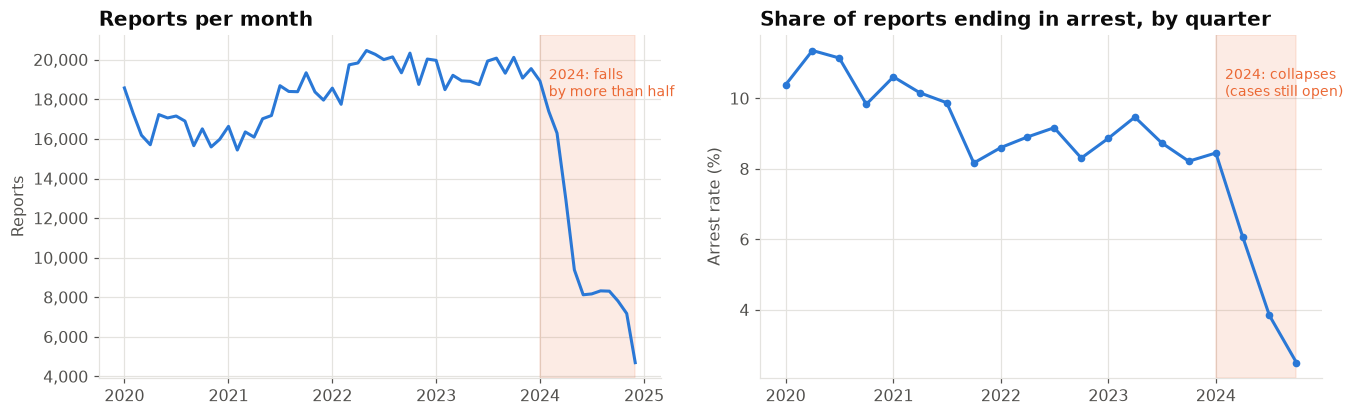

,reports,arrest_rate_%
p,,
2020,"199,847",10.7
2021,"209,876",9.7
2022,"235,259",8.7
2023,"232,345",8.8
2024,"127,567",6.1


In [6]:
monthly, qrate = prof["monthly"], prof["quarterly_arrest_pct"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
x = monthly.index.to_timestamp()
axes[0].plot(x, monthly.values, color=vs.BLUE, lw=2)
axes[0].axvspan(pd.Timestamp("2024-01-01"), x.max(), color=vs.ORANGE, alpha=0.13)
axes[0].set_title("Reports per month"); axes[0].set_ylabel("Reports")
axes[0].text(pd.Timestamp("2024-02-01"), monthly.max() * 0.96, "2024: falls\nby more than half", fontsize=9, color=vs.ORANGE, va="top")
xq = qrate.index.to_timestamp()
axes[1].plot(xq, qrate.values, color=vs.BLUE, lw=2, marker="o", ms=4)
axes[1].axvspan(pd.Timestamp("2024-01-01"), xq.max(), color=vs.ORANGE, alpha=0.13)
axes[1].set_title("Share of reports ending in arrest, by quarter"); axes[1].set_ylabel("Arrest rate (%)")
axes[1].text(pd.Timestamp("2024-02-01"), qrate.max() * 0.96, "2024: collapses\n(cases still open)", fontsize=9, color=vs.ORANGE, va="top")
fig.tight_layout(); vs.savefig(fig, "03_why_2024_excluded"); plt.show()
display(prof["yearly"].style.format({"reports": "{:,.0f}", "arrest_rate_%": "{:.1f}"}))

**Decision.** Reports from 2024 are *right-censored*: they have had less time to reach an outcome (and recording of recent months is incomplete), so the arrest rate drops from ≈ 9 % to 2.5 %. Including them would make recent crime look "unsolved" and bias every outcome statistic. **The analysis window is therefore 1 Jan 2020 – 31 Dec 2023.**

In [7]:
del prof
gc.collect();

---
## 4 · Data cleaning & pre-processing

All cleaning lives in [`src/cleaning.py`](../src/cleaning.py) so it can be re-run from the command line. Each decision below is logged with the number of rows it affected.

| Problem | Decision | Why |
|---|---|---|
| Dates stored as text (`2021 Apr 11 12:00:00 AM`) | Parse month names with a lookup table | Does not depend on the computer's language settings |
| Victim age 0 / negative / > 100 | Set to *missing* (not 0) | 0 means "not recorded" (e.g. crimes without a human victim); keeping it would distort the mean and the models |
| Victim sex X, H, '-', blank | Group as **Unknown** | Only M/F carry information |
| Coordinates 0,0 or outside Los Angeles | Set to missing | Portal documents 0,0 as "unknown" |
| Weapon blank | Means *no weapon recorded* → flag + category | Blank is informative, not an error |
| `Status` codes | Map to Arrest / Cleared-no-arrest / Investigation continuing; drop the 7 rows with rare `UNK`/`CC` codes | Needed for the target variable |
| 2024 incidents | Exclude | See stage 3 |
| Premises (306 values) | Keep 20 most common, rest → OTHER | Avoids hundreds of tiny categories |

In [8]:
t0 = time.time()
df = cleaning.build(force=False)        # reads the CSV the first time, then a fast parquet cache
log_path = ROOT / "outputs" / "tables" / "cleaning_log.json"
print(f"Clean table ready in {time.time() - t0:.0f}s -> {df.shape[0]:,} rows x {df.shape[1]} columns")
if log_path.exists():
    log = json.loads(log_path.read_text())
    rows = []
    for s in log["steps"]:
        detail = ", ".join(f"{k.replace('_', ' ')}: {v:,}" if isinstance(v, int) else f"{k.replace('_', ' ')}: {v}"
                           for k, v in s.items() if k != "step")
        rows.append((s["step"], detail))
    display(pd.DataFrame(rows, columns=["Cleaning step", "Result"]).style.hide(axis="index"))
    md_(f"**{log['rows_raw']:,} raw rows → {log['rows_clean']:,} analysis rows** "
        f"(incidents {log['date_range'][0]} to {log['date_range'][1]}); overall arrest rate **{log['arrest_rate']:.1%}**.")
    KEY["rows_clean"] = log["rows_clean"]; KEY["arrest_rate"] = log["arrest_rate"]

Clean table ready in 0s -> 877,322 rows x 31 columns


Cleaning step,Result
Drop duplicate report numbers (DR_NO),rows removed: 0
Parse dates (locale-independent),unparseable rows dropped: 0
Report lag = date reported - date occurred,negative lags set missing: 0
"Victim age: 0, negative or >100 is not a real age -> missing","values set missing: 269,316, share: 0.268"
"Victim sex: only M/F kept; X, H, '-' and blanks -> 'Unknown'","set unknown: 242,499"
"Coordinates: 0,0 or outside Los Angeles -> missing","values set missing: 2,240"
Crime descriptions grouped by keyword rules,"unique descriptions: 140, groups: 13"
Weapon: blank Weapon Used Cd means none recorded (67% of rows),"rows without weapon: 677,678"
"Premise: keep the 20 most common, rest -> OTHER",kept: 20
Mocodes kept as text for the MO-pattern analysis,"rows without mocodes: 151,598"


**1,004,894 raw rows → 877,322 analysis rows** (incidents 2020-01-01 to 2023-12-31); overall arrest rate **9.4%**.

In [9]:
after = (df.isna().mean() * 100)
display(after[after > 0].sort_values(ascending=False).rename("missing %").to_frame().T)
display(df.dtypes.astype(str).value_counts().rename("columns").to_frame().T)

,vict_age,age_group,lat,lon
missing %,24.915,24.915,0.255,0.255


,category,int64,float64,int32,datetime64[ns],Int64,str
columns,12,8,4,3,2,1,1


Remaining missing values are genuine (victim age unknown, coordinates unknown, report lag) and are **kept as missing** – XGBoost and TabPFN handle them natively; Logistic Regression uses median imputation inside its own pipeline so that nothing leaks from test data.

---
## 5 · Data transformation & integration

**Feature engineering** – new variables derived from the raw columns:

| New feature | Built from | Use |
|---|---|---|
| `hour`, `dow`, `month`, `is_weekend`, `part_of_day` | `TIME OCC`, `DATE OCC` | When crime happens |
| `report_lag_days`, `log_report_lag` | `Date Rptd − DATE OCC` | How quickly the crime was reported (log-scaled because very skewed) |
| `crime_group`, `crime_class` | `Crm Cd Desc` (140 values) | 13 readable groups → Violent / Property / Fraud / Other |
| `weapon_used`, `weapon_group` | `Weapon Used Cd` | Firearm, knife, other object, physical force, unknown |
| `vict_descent` (grouped), `age_group` | `Vict Descent`, `Vict Age` | Readable demographic categories |
| `n_crime_codes`, `n_mo` | `Crm Cd 1-4`, `Mocodes` | Number of offences / MO codes in the report |
| `arrest` | `Status` | **Target:** 1 = adult or juvenile arrest |

**Integration** – lookup tables (descent codes, weapon-code ranges, status codes, crime-description rules) are joined onto the report table. The crime-group rules are transparent keyword rules in [`src/crime_groups.py`](../src/crime_groups.py); we chose rules over a language model because there are only 140 descriptions, so every assignment can be audited:

In [10]:
audit = (df.groupby("crime_group", observed=True)
           .agg(descriptions=("crime_desc", "nunique"), reports=("dr_no", "size"))
           .join(df.groupby("crime_group", observed=True)["crime_desc"].agg(
               lambda s: "; ".join(s.astype(str).value_counts().head(3).index.str.title().str.slice(0, 34))).rename("most common descriptions"))
           .sort_values("reports", ascending=False))
audit["reports"] = audit["reports"].map("{:,}".format)
display(audit)

,descriptions,reports,most common descriptions
crime_group,,,
Vehicle Theft & Break-ins,10,"219,615",Vehicle - Stolen; Burglary From Vehicle; Theft...
Assault & Battery,8,"182,456",Battery - Simple Assault; Assault With Deadly ...
Theft & Larceny,22,"114,783",Theft Plain - Petty ($950 & Under); Theft-Gran...
Vandalism & Arson,4,"78,535","Vandalism - Felony ($400 & Over, A; Vandalism ..."
Fraud & Identity Theft,20,"72,406","Theft Of Identity; Bunco, Grand Theft; Embezzl..."
Burglary,2,"57,070","Burglary; Burglary, Attempted"
Threats & Court Orders,8,"39,427",Criminal Threats - No Weapon Displ; Violation ...
Robbery & Extortion,3,"36,207",Robbery; Attempted Robbery; Extortion
Other / Public Order,18,"24,603",Trespassing; Other Miscellaneous Crime; Distur...


In [11]:
display(df.sample(5, random_state=SEED).T.rename(columns=lambda c: f"sample {c}")[:])

,sample 189317,sample 271997,sample 664201,sample 285312,sample 682471
dr_no,200510776,211224165,231013267,211707679,230514693
date_occ,2020-06-18 00:00:00,2021-11-28 00:00:00,2023-08-25 00:00:00,2021-04-16 00:00:00,2023-10-13 00:00:00
date_rptd,2020-06-19 00:00:00,2021-11-28 00:00:00,2023-08-25 00:00:00,2021-04-16 00:00:00,2023-10-15 00:00:00
year,2020,2021,2023,2021,2023
month,6,11,8,4,10
dow,3,6,4,4,4
is_weekend,0,1,0,0,0
hour,20,7,18,5,16
part_of_day,Evening (18-23),Morning (6-11),Evening (18-23),Night (0-5),Afternoon (12-17)
area,Harbor,77th Street,West Valley,Devonshire,Harbor


---
## 6 · Exploratory data analysis (EDA)

Blue shows the main measure; **orange highlights arrests**. Arrest rates always come with 95 % Wilson confidence intervals.

In [12]:
def rate_table(col):
    """Arrest count, size, rate and 95% Wilson CI per category."""
    g = df.groupby(col, observed=True)["arrest"].agg(arrests="sum", reports="size")
    g["rate"] = g["arrests"] / g["reports"] * 100
    lo, hi = su.wilson_ci(g["arrests"], g["reports"])
    g["lo"], g["hi"] = lo * 100, hi * 100
    return g

DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
kpi = pd.Series({
    "Reports analysed": f"{len(df):,}",
    "Period": f"{df.date_occ.min():%d %b %Y} – {df.date_occ.max():%d %b %Y}",
    "LAPD areas": df.area.nunique(),
    "Distinct crime descriptions": df.crime_desc.nunique(),
    "Violent share": f"{(df.crime_class == 'Violent').mean():.1%}",
    "Arrest rate": f"{df.arrest.mean():.1%}",
    "Median days to report": f"{df.report_lag_days.median():.0f}",
    "Reports with a weapon recorded": f"{df.weapon_used.mean():.1%}",
}, name="value")
display(kpi.to_frame())

,value
Reports analysed,"877,322"
Period,01 Jan 2020 – 31 Dec 2023
LAPD areas,21
Distinct crime descriptions,138
Violent share,35.4%
Arrest rate,9.4%
Median days to report,1
Reports with a weapon recorded,34.6%


### 6.1 Time – trend, season, hour of day

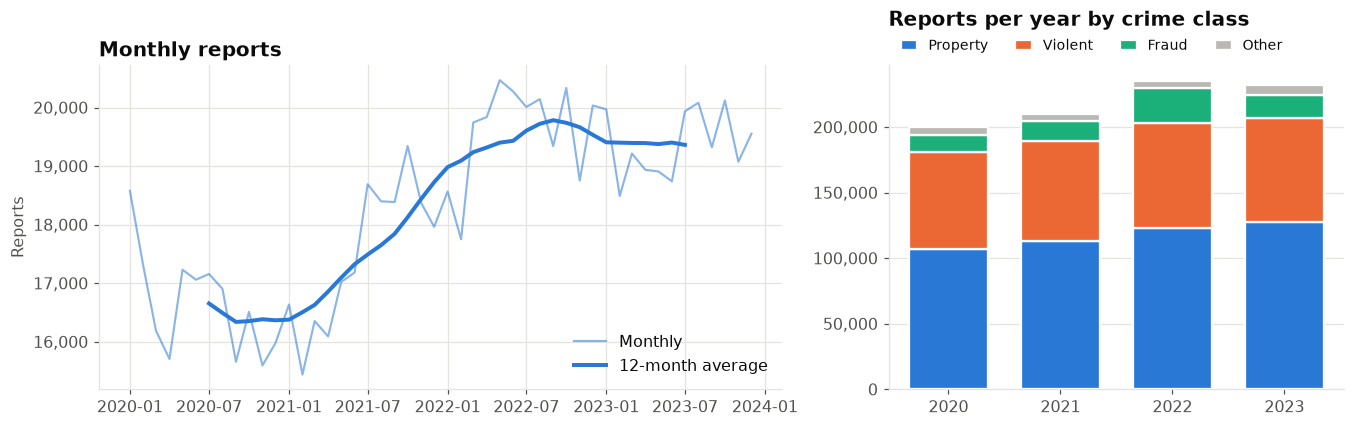

crime_class,Property %,Violent %,Fraud %,Other %,total
year,,,,,
2020,53.700,36.900,6.500,2.900,199847
2021,53.800,36.400,7.100,2.700,209876
2022,52.100,34.200,11.200,2.400,235257
2023,54.800,34.200,7.800,3.300,232342


In [13]:
monthly = df.groupby(df.date_occ.dt.to_period("M")).size()
mx = monthly.index.to_timestamp()
by_year = df.groupby(["year", "crime_class"], observed=True).size().unstack()[["Property", "Violent", "Fraud", "Other"]]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].plot(mx, monthly.values, color=vs.BLUE, lw=1.4, alpha=0.55, label="Monthly")
axes[0].plot(mx, monthly.rolling(12, center=True).mean().values, color=vs.BLUE, lw=2.6, label="12-month average")
axes[0].set_title("Monthly reports"); axes[0].set_ylabel("Reports"); axes[0].legend(loc="lower right")
bottom = np.zeros(len(by_year))
for col, color in zip(by_year.columns, [vs.BLUE, vs.ORANGE, vs.AQUA, "#b9b8b2"]):
    axes[1].bar(by_year.index.astype(str), by_year[col], bottom=bottom, color=color, label=col, edgecolor="white", linewidth=1.5, width=0.7)
    bottom += by_year[col].to_numpy()
axes[1].set_title("Reports per year by crime class", pad=26); axes[1].legend(ncol=4, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); vs.savefig(fig, "06_time_trend"); plt.show()
display((by_year.div(by_year.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %").assign(total=by_year.sum(axis=1)))

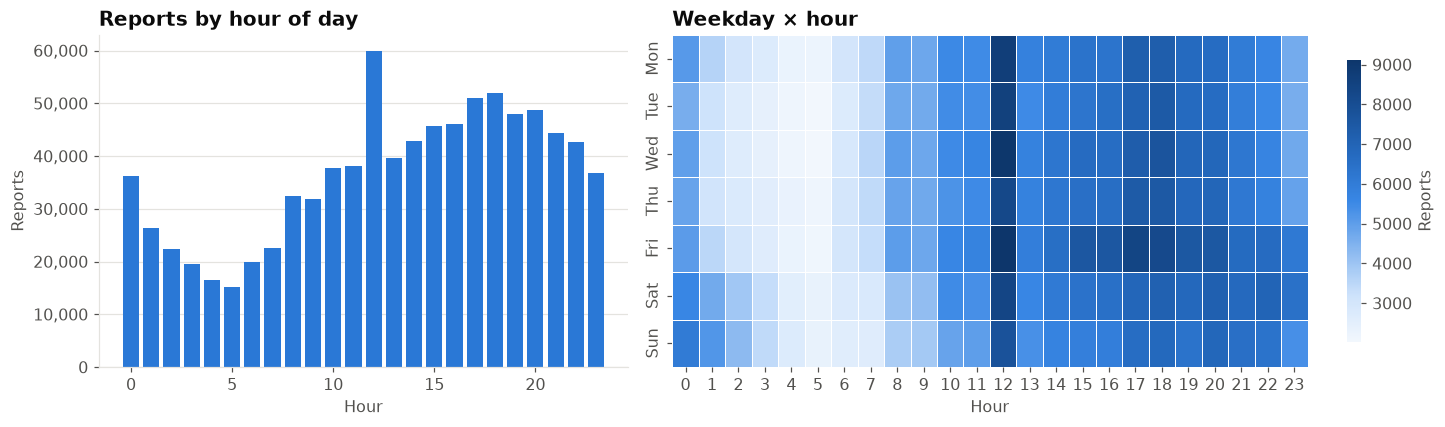

The busiest hour is **12:00** (59,981 reports). Noon and midnight stand out because the time is often unknown and recorded as 12:00 / 00:00 – a recording artefact, not real crime peaks.

In [14]:
hour_counts = df.groupby("hour").size()
heat = df.groupby(["dow", "hour"]).size().unstack()
heat.index = DOW
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(hour_counts.index, hour_counts.values, color=vs.BLUE, width=0.8)
axes[0].set_title("Reports by hour of day"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Reports")
axes[0].grid(axis="x", visible=False)
sns.heatmap(heat, cmap=vs.SEQ_BLUE, ax=axes[1], cbar_kws={"label": "Reports", "shrink": 0.85}, linewidths=0.6, linecolor="white")
axes[1].set_title("Weekday × hour"); axes[1].set_xlabel("Hour"); axes[1].set_ylabel("")
axes[1].grid(False)
fig.tight_layout(); vs.savefig(fig, "06_time_hour_heatmap"); plt.show()
peak = hour_counts.idxmax()
md_(f"The busiest hour is **{peak}:00** ({hour_counts.max():,} reports). Noon and midnight stand out because "
    f"the time is often unknown and recorded as 12:00 / 00:00 – a recording artefact, not real crime peaks.")

### 6.2 Place – areas and map

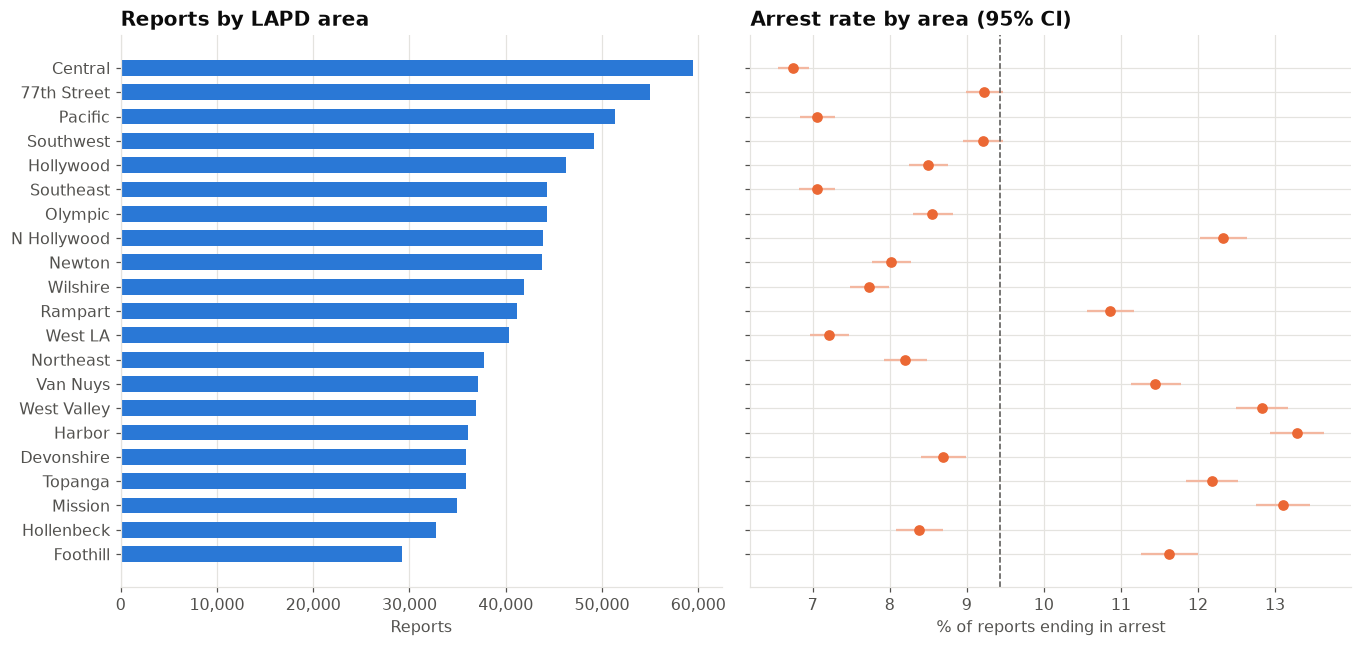

In [15]:
area = rate_table("area").sort_values("reports")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6), sharey=True)
axes[0].barh(area.index, area.reports, color=vs.BLUE, height=0.65)
axes[0].set_title("Reports by LAPD area"); axes[0].set_xlabel("Reports"); axes[0].grid(axis="y", visible=False)
axes[1].errorbar(area.rate, range(len(area)), xerr=[area.rate - area.lo, area.hi - area.rate], fmt="o", color=vs.ORANGE, ecolor="#f3b7a0", capsize=0, ms=6)
axes[1].axvline(df.arrest.mean() * 100, color=vs.INK_2, lw=1, ls="--")
axes[1].set_title("Arrest rate by area (95% CI)"); axes[1].set_xlabel("% of reports ending in arrest")
axes[1].set_yticks(range(len(area))); axes[1].set_yticklabels(area.index)
fig.tight_layout(); vs.savefig(fig, "06_area"); plt.show()

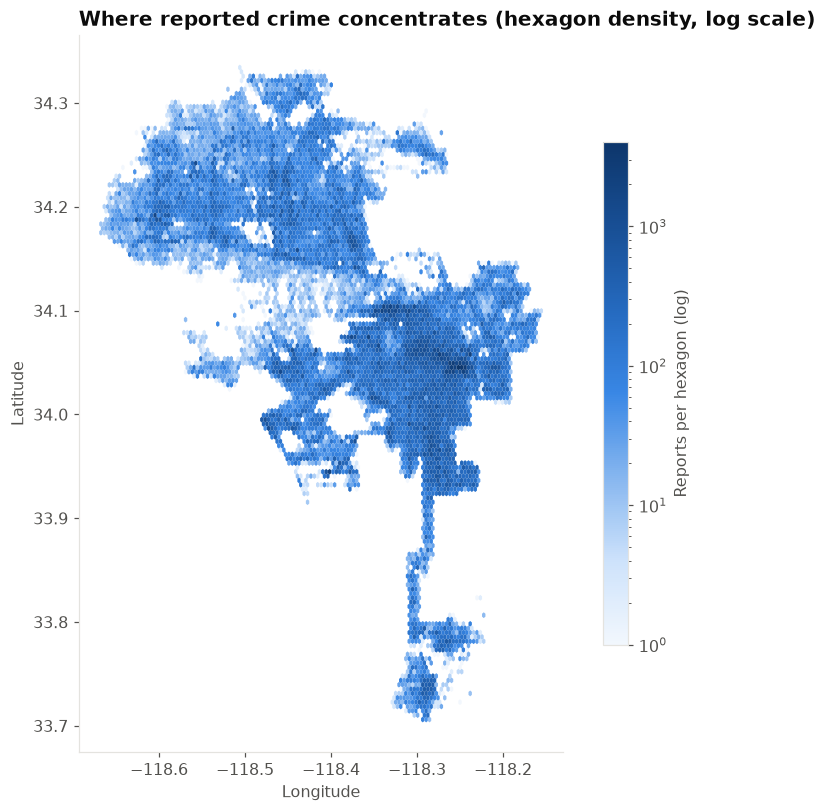

In [16]:
g = df.dropna(subset=["lat", "lon"])
fig, ax = plt.subplots(figsize=(7.5, 7.5))
hb = ax.hexbin(g.lon, g.lat, gridsize=130, bins="log", cmap=vs.SEQ_BLUE, mincnt=1, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(34.05)))
ax.set_title("Where reported crime concentrates (hexagon density, log scale)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(False)
fig.colorbar(hb, ax=ax, shrink=0.7, label="Reports per hexagon (log)")
fig.tight_layout(); vs.savefig(fig, "06_map_density"); plt.show()

### 6.3 Crime types and outcomes

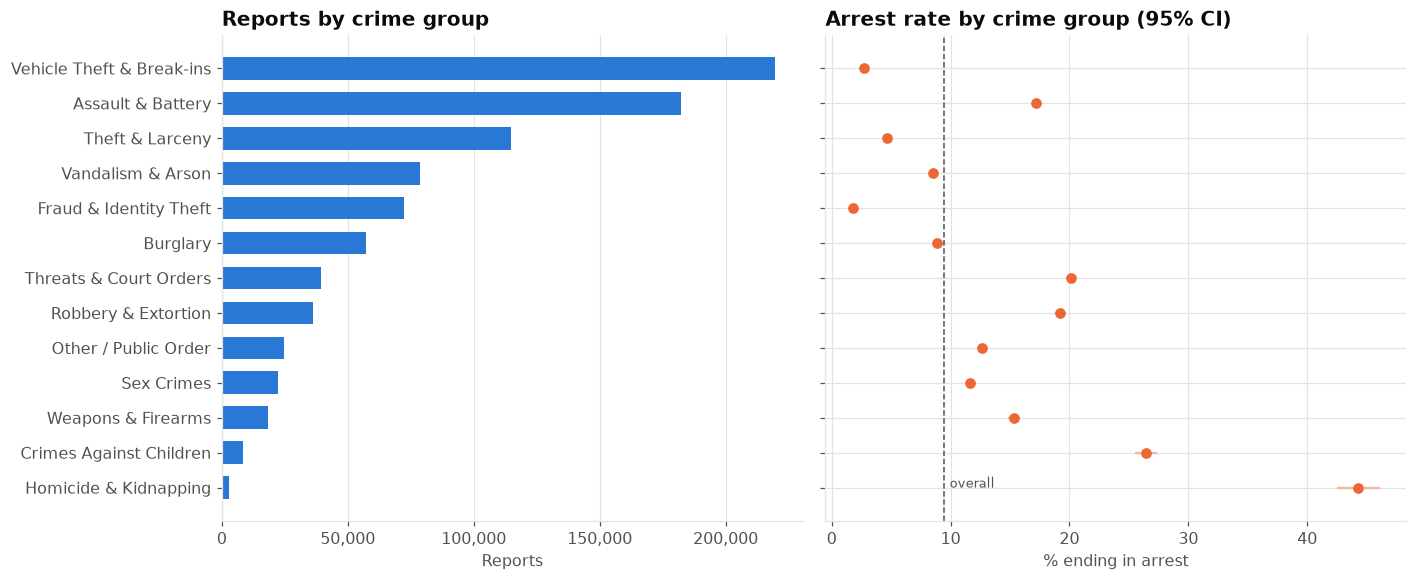

In [17]:
cg = rate_table("crime_group").sort_values("reports")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=True)
axes[0].barh(cg.index, cg.reports, color=vs.BLUE, height=0.65)
axes[0].set_title("Reports by crime group"); axes[0].set_xlabel("Reports"); axes[0].grid(axis="y", visible=False)
axes[1].errorbar(cg.rate, range(len(cg)), xerr=[cg.rate - cg.lo, cg.hi - cg.rate], fmt="o", color=vs.ORANGE, ecolor="#f3b7a0", ms=6)
axes[1].axvline(df.arrest.mean() * 100, color=vs.INK_2, lw=1, ls="--")
axes[1].text(df.arrest.mean() * 100 + 0.5, 0.0, "overall", fontsize=8.5, color=vs.INK_2)
axes[1].set_title("Arrest rate by crime group (95% CI)"); axes[1].set_xlabel("% ending in arrest")
axes[1].set_yticks(range(len(cg))); axes[1].set_yticklabels(cg.index)
fig.tight_layout(); vs.savefig(fig, "06_crime_group"); plt.show()
KEY["arrest_by_group"] = {k: round(float(v), 2) for k, v in cg["rate"].items()}

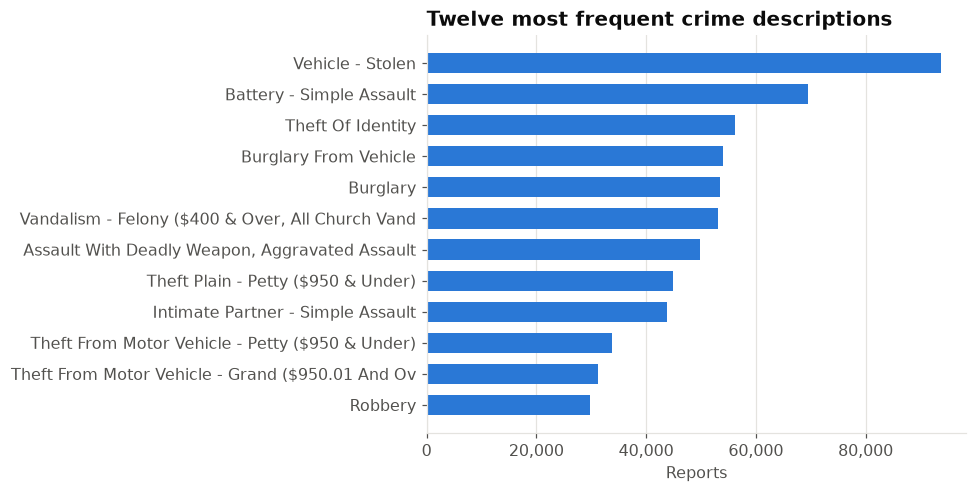

In [18]:
top = df.crime_desc.astype(str).value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top.index.str.title().str.slice(0, 48), top.values, color=vs.BLUE, height=0.65)
ax.set_title("Twelve most frequent crime descriptions"); ax.set_xlabel("Reports"); ax.grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "06_top_crimes"); plt.show()

### 6.4 Victims

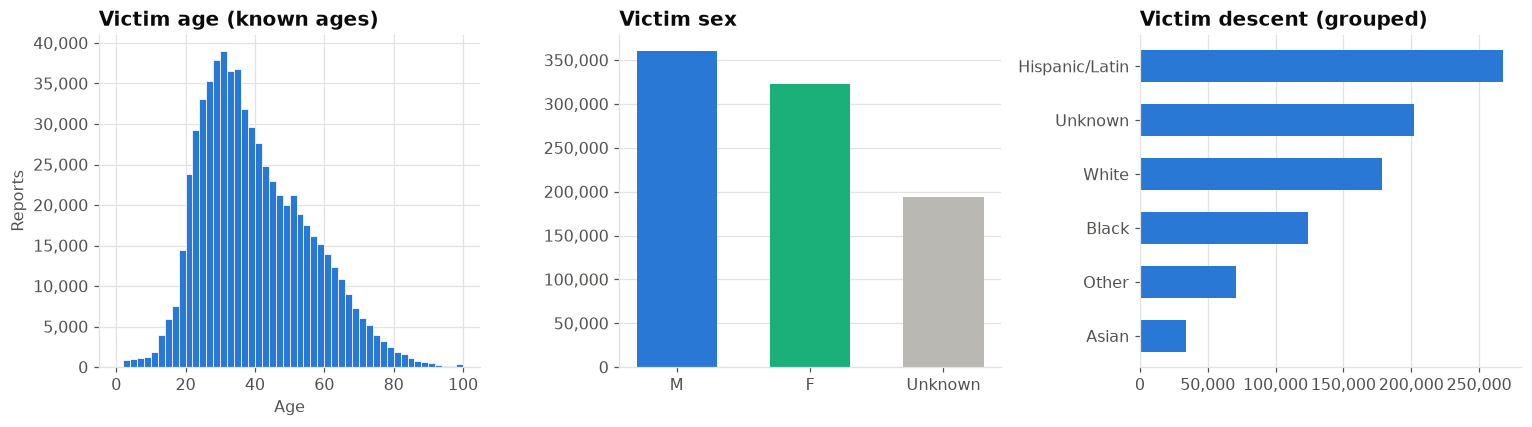

Victim age is known for **75%** of reports; the median known age is **37**. Sex is unknown for **22%** and descent for **23%** – concentrated in crimes where no person is usually present: **53%** of vehicle-crime reports have no victim sex.

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df.vict_age.dropna(), bins=np.arange(0, 101, 2), color=vs.BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_title("Victim age (known ages)"); axes[0].set_xlabel("Age"); axes[0].set_ylabel("Reports")
sx = df.vict_sex.astype(str).value_counts()
axes[1].bar(sx.index, sx.values, color=[vs.BLUE, vs.AQUA, "#b9b8b2"][:len(sx)], width=0.6)
axes[1].set_title("Victim sex"); axes[1].grid(axis="x", visible=False)
ds = df.vict_descent.astype(str).value_counts().sort_values()
axes[2].barh(ds.index, ds.values, color=vs.BLUE, height=0.6)
axes[2].set_title("Victim descent (grouped)"); axes[2].grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "06_victims"); plt.show()
md_(f"Victim age is known for **{df.vict_age.notna().mean():.0%}** of reports; the median known age is **{df.vict_age.median():.0f}**. "
    f"Sex is unknown for **{(df.vict_sex == 'Unknown').mean():.0%}** and descent for **{(df.vict_descent == 'Unknown').mean():.0%}** – "
    f"concentrated in crimes where no person is usually present: **{(df[df.crime_group == 'Vehicle Theft & Break-ins'].vict_sex == 'Unknown').mean():.0%}** of vehicle-crime reports have no victim sex.")

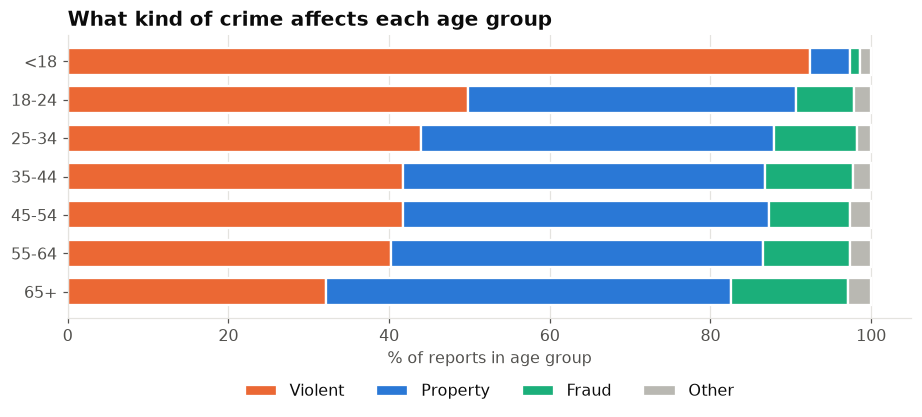

In [20]:
ag = (df.dropna(subset=["age_group"]).groupby(["age_group", "crime_class"], observed=True).size().unstack(fill_value=0))
ag = ag[["Violent", "Property", "Fraud", "Other"]]
ag_pct = ag.div(ag.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8.5, 4))
left = np.zeros(len(ag_pct))
for col, color in zip(ag_pct.columns, [vs.ORANGE, vs.BLUE, vs.AQUA, "#b9b8b2"]):
    ax.barh(ag_pct.index.astype(str), ag_pct[col], left=left, color=color, label=col, edgecolor="white", linewidth=1.5, height=0.7)
    left += ag_pct[col].to_numpy()
ax.set_xlabel("% of reports in age group"); ax.set_title("What kind of crime affects each age group")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18)); ax.grid(axis="y", visible=False); ax.invert_yaxis()
fig.tight_layout(); vs.savefig(fig, "06_age_vs_class"); plt.show()

### 6.5 Weapons, premises and reporting delay

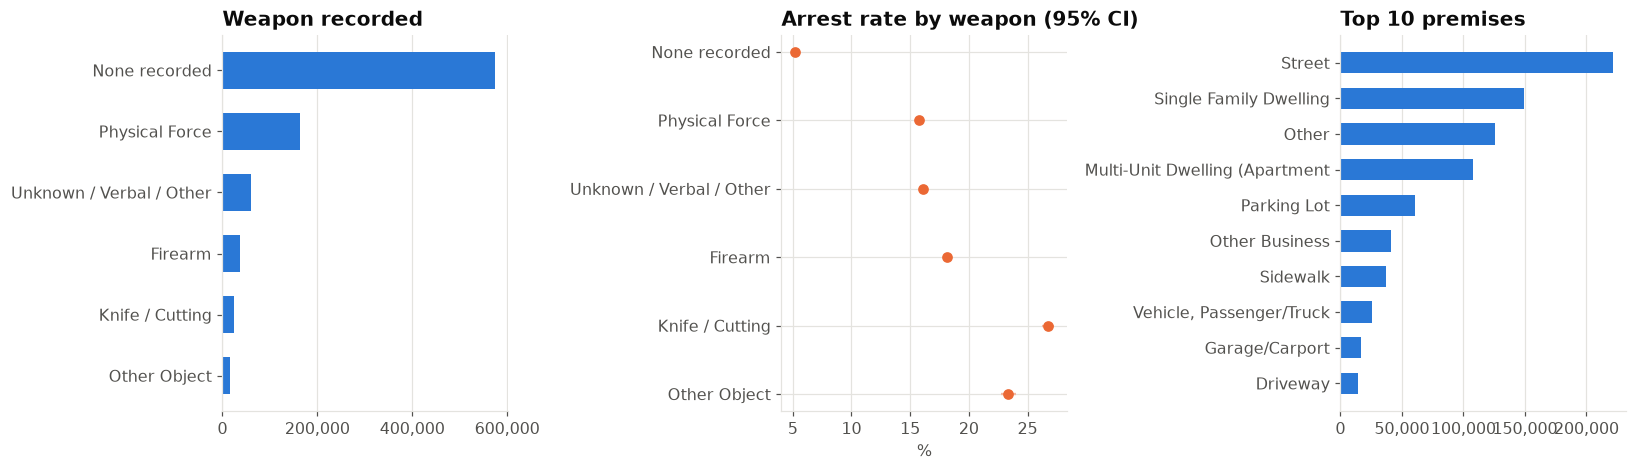

In [21]:
wg = rate_table("weapon_group").sort_values("reports")
pr = rate_table("premise").sort_values("reports").tail(10)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[0].barh(wg.index, wg.reports, color=vs.BLUE, height=0.6); axes[0].set_title("Weapon recorded"); axes[0].grid(axis="y", visible=False)
axes[1].errorbar(wg.rate, range(len(wg)), xerr=[wg.rate - wg.lo, wg.hi - wg.rate], fmt="o", color=vs.ORANGE, ecolor="#f3b7a0", ms=6)
axes[1].set_yticks(range(len(wg))); axes[1].set_yticklabels(wg.index); axes[1].set_title("Arrest rate by weapon (95% CI)"); axes[1].set_xlabel("%")
axes[2].barh(pr.index.str.title().str.slice(0, 30), pr.reports, color=vs.BLUE, height=0.6); axes[2].set_title("Top 10 premises"); axes[2].grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "06_weapons_premises"); plt.show()

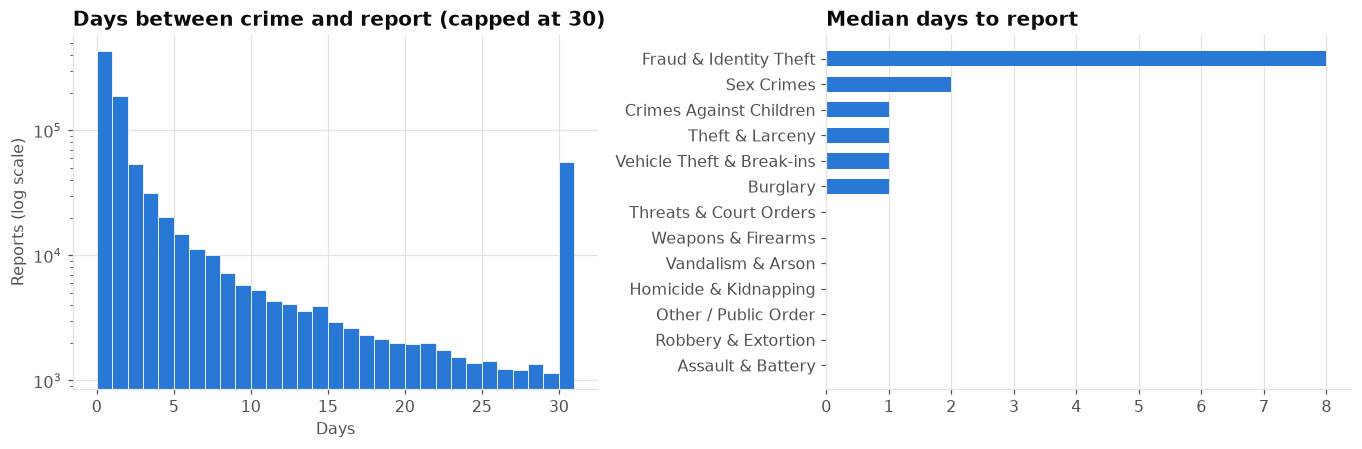

**49%** of crimes are reported the same day, but the distribution has a very long tail (mean 13 days, maximum 1,862 days). The longest delays are in fraud & identity theft (68 days on average), crimes against children (62 days on average), sex crimes (59 days on average).

In [22]:
lag = df.report_lag_days.dropna()
med_lag = df.groupby("crime_group", observed=True).report_lag_days.median().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].hist(lag.clip(upper=30), bins=np.arange(0, 32, 1), color=vs.BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_yscale("log"); axes[0].set_title("Days between crime and report (capped at 30)"); axes[0].set_xlabel("Days"); axes[0].set_ylabel("Reports (log scale)")
axes[1].barh(med_lag.index, med_lag.values, color=vs.BLUE, height=0.6); axes[1].set_title("Median days to report"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "06_report_lag"); plt.show()
md_(f"**{(lag == 0).mean():.0%}** of crimes are reported the same day, but the distribution has a very long tail "
    f"(mean {lag.mean():.0f} days, maximum {lag.max():,.0f} days). The longest delays are in "
    + ", ".join(f"{g.lower()} ({v:.0f} days on average)" for g, v in df.groupby("crime_group", observed=True).report_lag_days.mean().nlargest(3).items()) + ".")

### 6.6 Correlation between numeric variables

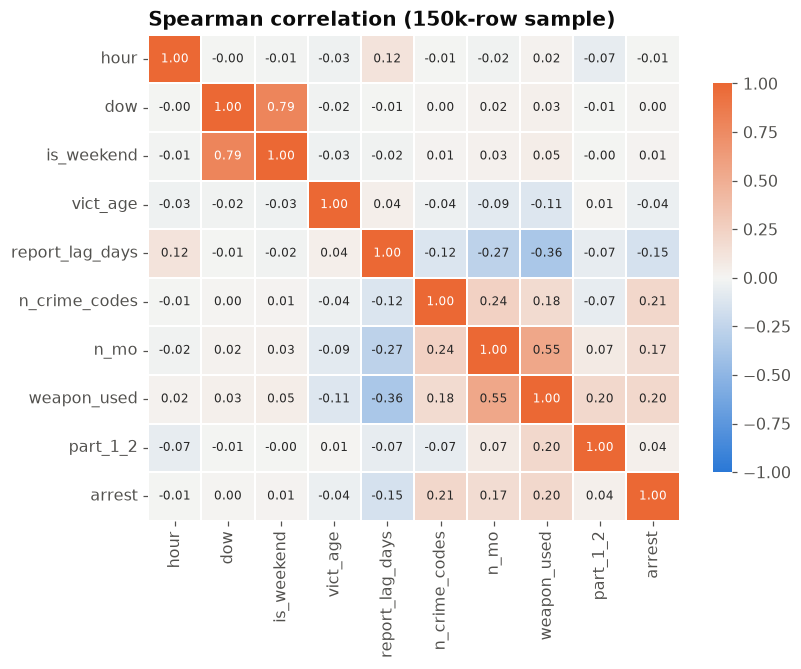

,n_crime_codes,weapon_used,n_mo,report_lag_days,vict_age,part_1_2,is_weekend,hour,dow
Spearman ρ with arrest,0.207,0.201,0.170,-0.152,-0.044,0.036,0.008,-0.005,0.001


In [23]:
num_cols = ["hour", "dow", "is_weekend", "vict_age", "report_lag_days", "n_crime_codes", "n_mo", "weapon_used", "part_1_2", "arrest"]
corr = df[num_cols].sample(150_000, random_state=SEED).astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.6, 6.2))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1, linecolor="white", ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation (150k-row sample)"); ax.grid(False)
fig.tight_layout(); vs.savefig(fig, "06_correlation"); plt.show()
display(corr["arrest"].drop("arrest").sort_values(key=abs, ascending=False).rename("Spearman ρ with arrest").to_frame().T)

---
## 7 · Statistical analysis

With ≈ 877 000 reports **almost any difference is statistically significant**, so a p-value alone says little. Each test below therefore reports an **effect size** – the quantity that tells us whether the difference *matters*:

* **Cramér's V** for category-vs-category (0.1 small · 0.3 medium · 0.5 large)
* **Rank-biserial r** for Mann-Whitney tests (|r| 0.1 small · 0.3 medium · 0.5 large)
* **Odds ratio with 95 % CI** for 2×2 comparisons

Non-parametric tests are used where the data are clearly skewed (age, reporting delay, daily counts). Significance level α = 0.05 with a Bonferroni correction for the number of tests.

In [24]:
results = []
def add_result(question, test, stat, p, effect_name, effect, note=""):
    results.append({"Question": question, "Test": test, "Statistic": stat, "p-value": p,
                    "Effect size": effect_name, "Value": effect, "Reading": note})

# 1-2, 5, 11: category vs arrest (chi-square + Cramer's V)
for label, col in [("Does the arrest rate depend on crime type?", "crime_group"),
                   ("... on the LAPD area?", "area"),
                   ("... on the time of day?", "part_of_day"),
                   ("... on the type of premise?", "premise"),
                   ("... on the weapon recorded?", "weapon_group")]:
    r = su.chi2_association(df[col], df["arrest"])
    add_result(label, f"Chi-square (df={r['dof']})", r["chi2"], r["p_value"], "Cramér's V", r["cramers_v"], su.cramers_v_label(r["cramers_v"]))

known = df[df.vict_descent != "Unknown"]
r = su.chi2_association(known["vict_descent"], known["arrest"])
add_result("... on victim descent (known only)?", f"Chi-square (df={r['dof']})", r["chi2"], r["p_value"], "Cramér's V", r["cramers_v"], su.cramers_v_label(r["cramers_v"]))

# sex (M vs F) as 2x2 with odds ratio
mf = df[df.vict_sex.isin(["M", "F"])]
r = su.chi2_association(mf["vict_sex"].astype(str), mf["arrest"])
fa, fn = mf[mf.vict_sex == "F"].arrest.agg(["sum", "size"]); ma, mn = mf[mf.vict_sex == "M"].arrest.agg(["sum", "size"])
orr, lo, hi = su.odds_ratio(fa, fn, ma, mn)
add_result("... on victim sex (F vs M)?", "Chi-square (df=1)", r["chi2"], r["p_value"], "Odds ratio F vs M", orr, f"95% CI {lo:.2f}-{hi:.2f}")

# weapon yes/no with odds ratio
wa, wn = df[df.weapon_used == 1].arrest.agg(["sum", "size"]); na, nn = df[df.weapon_used == 0].arrest.agg(["sum", "size"])
orr, lo, hi = su.odds_ratio(wa, wn, na, nn)
r = su.chi2_association(df["weapon_used"], df["arrest"])
add_result("Is a weapon-recorded report more likely to end in arrest?", "Chi-square (df=1)", r["chi2"], r["p_value"], "Odds ratio", orr, f"95% CI {lo:.2f}-{hi:.2f}")

# numeric vs arrest
for label, col in [("Do arrested and non-arrested cases differ in victim age?", "vict_age"),
                   ("... in reporting delay (days)?", "report_lag_days")]:
    a = df.loc[df.arrest == 1, col]; b = df.loc[df.arrest == 0, col]
    r = su.mann_whitney(a, b)
    add_result(label, "Mann-Whitney U", r["U"], r["p_value"], "Rank-biserial r", r["rank_biserial"],
               f"median {r['median_x']:.0f} (arrest) vs {r['median_y']:.0f} (no arrest)")

# volume questions
daily = df.groupby("date_occ").size()
wk = daily.index.dayofweek >= 5
r = su.mann_whitney(daily[wk].to_numpy(), daily[~wk].to_numpy())
add_result("Are weekends busier than weekdays (daily reports)?", "Mann-Whitney U", r["U"], r["p_value"], "Rank-biserial r", r["rank_biserial"],
           f"median {r['median_x']:.0f} (weekend) vs {r['median_y']:.0f} (weekday) per day")
m = df.groupby(df.date_occ.dt.to_period("M")).size()
tau, p_tau = stats.kendalltau(np.arange(len(m)), m.to_numpy())
slope = stats.linregress(np.arange(len(m)), m.to_numpy())
add_result("Is there a monotonic trend in monthly reports 2020-2023?", "Kendall tau", tau, p_tau, "Slope (reports/month per month)", slope.slope, f"tau={tau:.2f}")
rel = daily / daily.groupby(daily.index.year).transform("mean")
groups = [g.to_numpy() for _, g in rel.groupby(rel.index.month)]
h, p_h = stats.kruskal(*groups)
add_result("Does volume differ by calendar month (seasonality)?", "Kruskal-Wallis", h, p_h, "eta-squared (H/(n-1))", h / (len(rel) - 1), "daily volume relative to its year mean")

res = pd.DataFrame(results)
res["Significant (Bonferroni)"] = res["p-value"] < 0.05 / len(res)
res["p-value"] = res["p-value"].map(su.p_text)
res["Statistic"] = res["Statistic"].map("{:,.1f}".format)
res["Value"] = res["Value"].map("{:,.3f}".format)
display(res.style.hide(axis="index"))
res.to_csv(TABLES / "statistical_tests.csv", index=False)
KEY["tests"] = res[["Question", "Test", "p-value", "Effect size", "Value", "Reading"]].to_dict("records")

Question,Test,Statistic,p-value,Effect size,Value,Reading,Significant (Bonferroni)
Does the arrest rate depend on crime type?,Chi-square (df=12),"49,836.5",p < 0.001,Cramér's V,0.238,small,True
... on the LAPD area?,Chi-square (df=20),"4,698.0",p < 0.001,Cramér's V,0.073,negligible,True
... on the time of day?,Chi-square (df=3),78.8,p < 0.001,Cramér's V,0.009,negligible,True
... on the type of premise?,Chi-square (df=20),"6,484.0",p < 0.001,Cramér's V,0.086,negligible,True
... on the weapon recorded?,Chi-square (df=5),"38,664.9",p < 0.001,Cramér's V,0.210,small,True
... on victim descent (known only)?,Chi-square (df=4),"3,729.9",p < 0.001,Cramér's V,0.074,negligible,True
... on victim sex (F vs M)?,Chi-square (df=1),182.3,p < 0.001,Odds ratio F vs M,1.115,95% CI 1.10-1.13,True
Is a weapon-recorded report more likely to end in arrest?,Chi-square (df=1),"34,725.8",p < 0.001,Odds ratio,3.847,95% CI 3.79-3.90,True
Do arrested and non-arrested cases differ in victim age?,Mann-Whitney U,"17,436,254,058.0",p < 0.001,Rank-biserial r,-0.087,median 35 (arrest) vs 37 (no arrest),True
... in reporting delay (days)?,Mann-Whitney U,"23,841,966,858.5",p < 0.001,Rank-biserial r,-0.274,median 0 (arrest) vs 1 (no arrest),True


### Reading the results

* **Crime type and weapon are the two strongest associations with arrest** (Cramér's V ≈ 0.24 and 0.21 – small-to-medium effects, the largest of all variables tested). A report with a weapon recorded has **≈ 3.8× the odds** of ending in arrest.
* **Where and when matter much less.** LAPD area (V ≈ 0.07), premise (≈ 0.09) and time of day (≈ 0.01) are statistically significant only because the sample is huge – their effects are *negligible*. Likewise victim sex (odds ratio ≈ 1.1) and victim age (median 35 vs 37) barely differ between arrested and non-arrested cases.
* **Speed matters.** Cases that end in arrest are reported faster (median 0 vs 1 day, rank-biserial r ≈ −0.27, a small-to-medium effect): the sooner police hear about it, the more likely a suspect is found.
* **Volume.** Monthly reports rose steadily from 2020 to 2023 (Kendall τ ≈ 0.5, ≈ +84 reports per month each month) after the early-2020 dip, with only weak seasonality. **Weekends are *not* busier than weekdays** (medians 590 vs 592 reports/day, p = 0.997) – the daily rhythm, not the weekday, drives crime volume.
* Arrest rates are **associations, not causes**: they reflect what kinds of crime can be solved (an assault with a known suspect vs an anonymous car break-in) as much as policing choices. With ≈ 877 000 rows, **effect size, not the p-value, tells us what matters.**

---
## 8 · Pattern discovery: modus-operandi (MO) clusters

`Mocodes` is a list of numeric codes such as `0416 0334 2004 1822` describing *how* the crime was committed. The data set does not include what each code means, so a language model has no text to read. We use the classic text-mining recipe instead, treating each report as a "document" whose "words" are its MO codes:

1. **TF-IDF** – gives rare, distinctive codes more weight than codes found in almost every report.
2. **Truncated SVD** (15 components) – compresses the sparse code matrix into a dense space.
3. **K-Means** – groups reports with similar MO. The number of clusters *k* is chosen by the **silhouette score**.

Reports with no MO code (≈ 15 %) get their own label (−1). The model is fitted on a 150 000-report sample and then assigns a cluster to every report.

Fitted in 12s; chosen k = 9


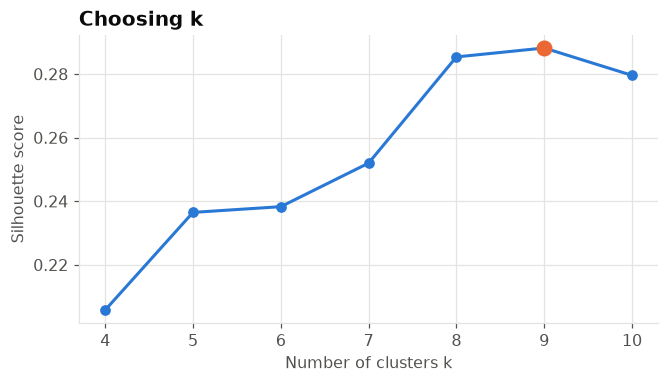

In [25]:
t0 = time.time()
mo_model = mo_patterns.fit_mo_model(df["mocodes"], random_state=SEED)
df["mo_cluster"] = mo_model.predict(df["mocodes"])
print(f"Fitted in {time.time() - t0:.0f}s; chosen k = {mo_model.k}")
scan = mo_model.silhouette_scan
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(scan.k, scan.silhouette, marker="o", color=vs.BLUE, lw=2)
best = scan.loc[scan.silhouette.idxmax()]
ax.scatter([best.k], [best.silhouette], color=vs.ORANGE, s=90, zorder=5)
ax.set_xlabel("Number of clusters k"); ax.set_ylabel("Silhouette score"); ax.set_title("Choosing k")
fig.tight_layout(); vs.savefig(fig, "08_silhouette"); plt.show()

In [26]:
prof = mo_patterns.describe_clusters(mo_model, df, df["mo_cluster"].to_numpy())
# readable, data-driven name: cluster id + dominant crime group
short = {"Vehicle Theft & Break-ins": "vehicle", "Theft & Larceny": "theft", "Assault & Battery": "assault",
         "Vandalism & Arson": "vandalism", "Fraud & Identity Theft": "fraud", "Other / Public Order": "other",
         "Robbery & Extortion": "robbery", "Burglary": "burglary", "Threats & Court Orders": "threats",
         "Sex Crimes": "sex crimes", "Weapons & Firearms": "weapons", "Crimes Against Children": "children",
         "Homicide & Kidnapping": "homicide"}
prof["name"] = [f"MO-{c}: " + short[r.top_crime_groups.split(" (")[0]] for c, r in zip(prof.cluster, prof.itertuples())]
NAMES = dict(zip(prof.cluster, prof.name)); NAMES[-1] = "No MO recorded"
df["mo_name"] = df["mo_cluster"].map(NAMES)
display(prof.drop(columns="cluster").set_index("name"))
prof.to_csv(TABLES / "mo_cluster_profiles.csv", index=False)
KEY["mo_profiles"] = prof.drop(columns="cluster").to_dict("records"); KEY["mo_k"] = int(mo_model.k)

,crimes,share_%,distinctive_MO_codes,top_crime_groups,arrest_rate_%,median_age
name,,,,,,
MO-0: vehicle,115621,15.300,0344 1300,Vehicle Theft & Break-ins (41%); Theft & Larce...,3.500,39.000
MO-1: assault,89213,11.800,0416 0446 0400 0913 1822,Assault & Battery (82%); Robbery & Extortion (9%),13.500,36.000
MO-2: assault,133039,17.600,1814 2000 0913 0444 0400 0416,Assault & Battery (54%); Threats & Court Order...,20.300,34.000
MO-3: vandalism,107903,14.300,0329 1307 1609 1300 1822 0344,Vandalism & Arson (67%); Vehicle Theft & Break...,7.300,39.000
MO-4: other,38177,5.100,1501 1822,Other / Public Order (30%); Vehicle Theft & Br...,9.300,39.000
MO-5: fraud,45526,6.000,0100 0922 0930 1822,Fraud & Identity Theft (98%); Theft & Larceny ...,0.700,38.000
MO-6: theft,33880,4.500,0325 1822 0344,Theft & Larceny (80%); Robbery & Extortion (12%),14.200,29.000
MO-7: theft,86686,11.500,0344 1822 1300,Theft & Larceny (41%); Vehicle Theft & Break-i...,2.700,37.000
MO-8: assault,105674,14.000,0334 1402 1822,Assault & Battery (30%); Fraud & Identity Thef...,15.200,36.000


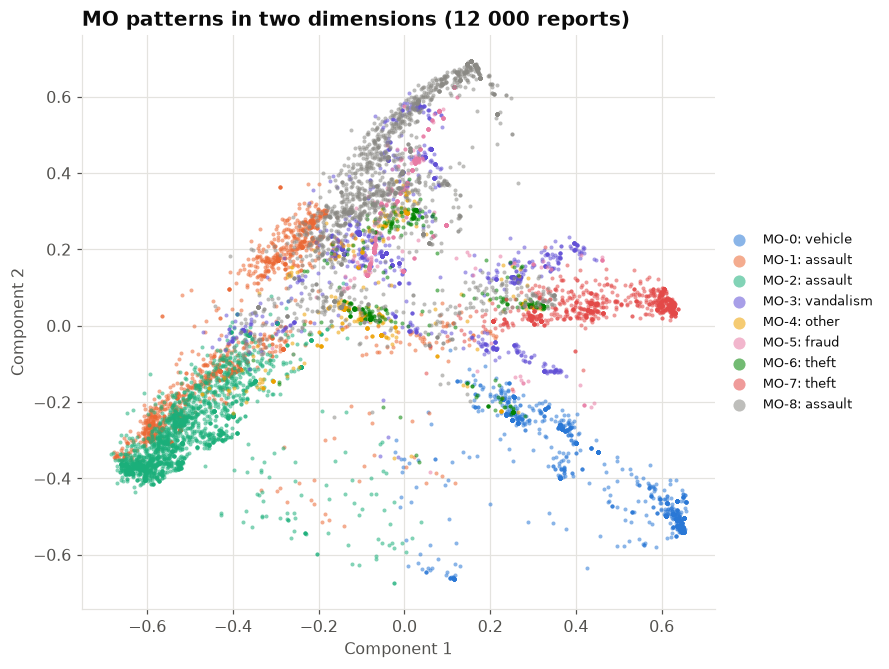

In [27]:
# 2-D picture of the MO space (PCA of the SVD embedding on a random sample)
samp = df[df.mo_cluster >= 0].sample(12_000, random_state=SEED)
Z = PCA(n_components=2, random_state=SEED).fit_transform(mo_model.embed(samp["mocodes"]))
fig, ax = plt.subplots(figsize=(8.2, 6.2))
order = sorted(samp.mo_cluster.unique())
for i, c in enumerate(order):
    m = (samp.mo_cluster == c).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=0.55, color=vs.CATEGORICAL[i % 8] if i < 8 else "#8a8984", label=NAMES[c], linewidths=0)
ax.set_title("MO patterns in two dimensions (12 000 reports)"); ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
ax.legend(markerscale=3, fontsize=8.5, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout(); vs.savefig(fig, "08_mo_scatter"); plt.show()

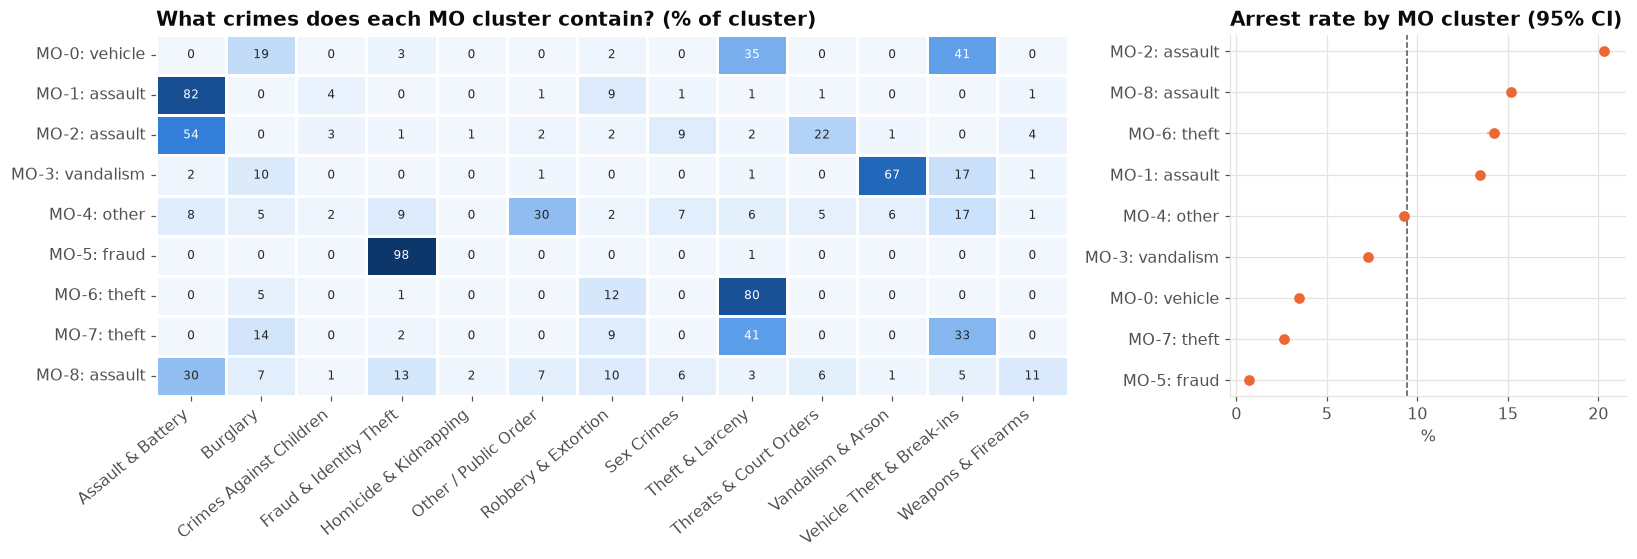

In [28]:
has = df[df.mo_cluster >= 0]
ct = pd.crosstab(has.mo_name, has.crime_group, normalize="index") * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.3, 1]})
sns.heatmap(ct, cmap=vs.SEQ_BLUE, annot=True, fmt=".0f", annot_kws={"size": 8}, linewidths=0.8, linecolor="white", cbar=False, ax=axes[0])
axes[0].set_title("What crimes does each MO cluster contain? (% of cluster)"); axes[0].set_xlabel(""); axes[0].set_ylabel(""); axes[0].grid(False)
plt.setp(axes[0].get_xticklabels(), rotation=40, ha="right")
cr = rate_table("mo_name").drop(index="No MO recorded", errors="ignore").sort_values("rate")
axes[1].errorbar(cr.rate, range(len(cr)), xerr=[cr.rate - cr.lo, cr.hi - cr.rate], fmt="o", color=vs.ORANGE, ecolor="#f3b7a0", ms=6)
axes[1].axvline(df.arrest.mean() * 100, color=vs.INK_2, lw=1, ls="--")
axes[1].set_yticks(range(len(cr))); axes[1].set_yticklabels(cr.index); axes[1].set_title("Arrest rate by MO cluster (95% CI)"); axes[1].set_xlabel("%")
fig.tight_layout(); vs.savefig(fig, "08_mo_profiles"); plt.show()

**Does MO tell us something beyond the crime type?** Inside one crime group (assault), do different MO clusters still have different arrest rates and different places/times? If yes, the MO codes carry independent information.

In [29]:
rows = []
for g in ["Assault & Battery", "Theft & Larceny"]:
    sub = has[has.crime_group == g]
    r = su.chi2_association(sub["mo_name"], sub["arrest"])
    t = sub.groupby("mo_name").arrest.agg(["mean", "size"]); t = t[t["size"] >= 500]
    rows.append({"Within crime group": g, "MO clusters compared": len(t), "Lowest arrest rate": f"{t['mean'].min():.1%}",
                 "Highest arrest rate": f"{t['mean'].max():.1%}", "Chi-square p": su.p_text(r["p_value"]), "Cramér's V": round(r["cramers_v"], 3)})
display(pd.DataFrame(rows).style.hide(axis="index"))

for label, col in [("MO cluster vs crime group", "crime_group"), ("MO cluster vs LAPD area", "area"),
                   ("MO cluster vs part of day", "part_of_day"), ("MO cluster vs arrest", "arrest")]:
    r = su.chi2_association(has["mo_name"], has[col])
    print(f"{label:28s} Cramér's V = {r['cramers_v']:.3f}  ({su.cramers_v_label(r['cramers_v'])}), {su.p_text(r['p_value'])}")

Within crime group,MO clusters compared,Lowest arrest rate,Highest arrest rate,Chi-square p,Cramér's V
Assault & Battery,5,12.3%,22.0%,p < 0.001,0.117000
Theft & Larceny,8,1.4%,11.7%,p < 0.001,0.197000


MO cluster vs crime group    Cramér's V = 0.549  (large), p < 0.001
MO cluster vs LAPD area      Cramér's V = 0.167  (small), p < 0.001


MO cluster vs part of day    Cramér's V = 0.088  (negligible), p < 0.001
MO cluster vs arrest         Cramér's V = 0.217  (small), p < 0.001


---
## 9 · Modelling – predicting whether a report ends in an arrest

**Task.** Binary classification, `arrest` = 1 for about 9 % of reports. Only information available **when the crime is reported** is used as input – nothing derived from the case outcome (`Status`) – so the model is not "cheating".

**Features (20):** time (hour, weekday, month, weekend), victim (age, sex, descent), crime (group, detailed description, number of offences, FBI part), place (area, premise, latitude/longitude), weapon (used, type), reporting delay, number of MO codes and the **MO cluster** discovered in stage 8.

**Three models of increasing sophistication**

| Model | Idea |
|---|---|
| **Logistic Regression** | Linear baseline (one-hot categories, class-weighted). Anything fancier must beat this. |
| **XGBoost** | Gradient-boosted decision trees – the standard strong model for tabular data. Trained on all training rows with early stopping. |
| **TabPFN v2 (transformer)** | A transformer **pre-trained on millions of synthetic tables**. It is *not* trained on our data by gradient descent; the training rows are given to it as context and it predicts new rows in one forward pass (*in-context learning*). Limited to a few thousand context rows on a CPU. |

**Data split.** 80 % train / 20 % test, stratified so both keep the 9.4 % arrest rate; 10 % of the training part is held out for early stopping and for choosing the decision threshold – **the test set is never used for tuning.**

Because TabPFN can only use a few thousand rows on a CPU, we also train a **small XGBoost on exactly the same rows**. That is the fair head-to-head: *with the same limited data, does the transformer do better than trees?*

In [30]:
X, y = modeling.make_xy(df)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.10, stratify=y_tr, random_state=SEED + 1)
print(f"train {len(X_fit):,} | validation {len(X_val):,} | test {len(X_te):,} | arrest rate train {y_fit.mean():.2%}, test {y_te.mean():.2%}")

train 631,671 | validation 70,186 | test 175,465 | arrest rate train 9.43%, test 9.43%


In [31]:
# ---- 1. Logistic Regression (baseline)
lr, t_lr = modeling.timed(modeling.fit_logistic, X_fit, y_fit)
p_lr = lr.predict_proba(X_te)[:, 1]
thr_lr = modeling.best_f1_threshold(y_val, lr.predict_proba(X_val)[:, 1])
print(f"Logistic Regression trained in {t_lr}s")

# ---- 2. XGBoost on all training rows
xgb, t_xgb = modeling.timed(modeling.fit_xgboost, X_fit, y_fit, X_val, y_val, SEED)
p_xgb = xgb.predict_proba(X_te)[:, 1]
thr_xgb = modeling.best_f1_threshold(y_val, xgb.predict_proba(X_val)[:, 1])
print(f"XGBoost trained in {t_xgb}s ({xgb.best_iteration + 1} trees after early stopping)")

Logistic Regression trained in 5.0s


XGBoost trained in 47.3s (482 trees after early stopping)


In [32]:
# ---- 3. TabPFN (transformer) and the same-data XGBoost
rng = np.random.default_rng(SEED)
ctx = rng.choice(len(X_fit), TABPFN_N_TRAIN, replace=False)     # rows given to the models
sub = rng.choice(len(X_te), TABPFN_N_TEST, replace=False)       # test rows used for the comparison
Xc, yc, Xs, ys = X_fit.iloc[ctx], y_fit[ctx], X_te.iloc[sub], y_te[sub]

xgb_small, t_xs = modeling.timed(modeling.fit_xgboost_small, Xc, yc, SEED)
p_xs = xgb_small.predict_proba(Xs)[:, 1]

p_tab, t_tab = None, None
if RUN_TABPFN and modeling.tabpfn_available():
    try:
        tab, t_fit = modeling.timed(modeling.fit_tabpfn, Xc, yc, 4, SEED)
        p_tab, t_pred = modeling.timed(modeling.predict_tabpfn, tab, Xs)
        t_tab = t_fit + t_pred
        print(f"TabPFN: fit {t_fit}s + predict {len(Xs):,} rows {t_pred}s (CPU)")
    except Exception as e:      # e.g. weights cannot be downloaded offline
        print("TabPFN skipped:", type(e).__name__, str(e)[:200])
else:
    print("TabPFN skipped (RUN_TABPFN=False or PyTorch/TabPFN not installed).")

TabPFN: fit 0.2s + predict 1,500 rows 130.8s (CPU)


---
## 10 · Evaluation

Because only ≈ 9 % of reports end in arrest, **accuracy is misleading** (always predicting "no arrest" scores 91 %). We use:

* **ROC-AUC** – chance that a random arrested case is ranked above a random non-arrested one (0.5 = coin flip).
* **PR-AUC (average precision)** – precision/recall trade-off; the baseline equals the arrest rate (≈ 0.09), so it is very demanding for rare events.
* **Precision / recall @ top 9 %** – "if investigators could prioritise the top 9 % of reports by score, how many arrests would that list catch?"
* **F1** at a threshold chosen on the *validation* set.

### 10.1 All models on the full test set (175 000 reports)

In [33]:
prev = float(y_fit.mean())
rows = []
for name, p, thr, secs in [("Logistic Regression", p_lr, thr_lr, t_lr), ("XGBoost", p_xgb, thr_xgb, t_xgb)]:
    m = modeling.metrics(y_te, p, thr, name, secs)
    pk, rk = modeling.precision_recall_at_prevalence(y_te, p, prev)
    rows.append({"Model": name, "ROC-AUC": m["ROC-AUC"], "PR-AUC": m["PR-AUC"], "F1": m["F1"], "Precision": m["precision"],
                 "Recall": m["recall"], "Precision @top 9%": pk, "Recall @top 9%": rk, "Train time (s)": secs})
full = pd.DataFrame(rows).set_index("Model")
display(full.style.format("{:.3f}", subset=[c for c in full.columns if c != "Train time (s)"]).highlight_max(axis=0, color="#cde2fb", subset=["ROC-AUC", "PR-AUC", "F1"]))
full.to_csv(TABLES / "model_metrics_full_test.csv")
KEY["full_test"] = full.reset_index().to_dict("records")
KEY["baseline_pr_auc"] = float(y_te.mean())

,ROC-AUC,PR-AUC,F1,Precision,Recall,Precision @top 9%,Recall @top 9%,Train time (s)
Model,,,,,,,,
Logistic Regression,0.814,0.333,0.383,0.305,0.513,0.364,0.364,5.000000
XGBoost,0.842,0.390,0.422,0.354,0.524,0.409,0.409,47.300000


### 10.2 The transformer comparison – identical small training set and identical test rows

In [34]:
P = {"Logistic Regression (all rows)": p_lr[sub], "XGBoost (all rows)": p_xgb[sub], f"XGBoost ({TABPFN_N_TRAIN:,} rows)": p_xs}
if p_tab is not None:
    P[f"TabPFN transformer ({TABPFN_N_TRAIN:,} rows)"] = p_tab
rows = []
for name, p in P.items():
    lo, hi = modeling.bootstrap_auc_ci(ys, p, n_boot=500)
    pk, rk = modeling.precision_recall_at_prevalence(ys, p, prev)
    rows.append({"Model": name, "ROC-AUC": modeling.roc_auc_score(ys, p), "AUC 95% CI": f"{lo:.3f} – {hi:.3f}",
                 "PR-AUC": modeling.average_precision_score(ys, p), "Precision @top 9%": pk, "Recall @top 9%": rk})
cmp_ = pd.DataFrame(rows).set_index("Model")
display(cmp_.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Precision @top 9%": "{:.3f}", "Recall @top 9%": "{:.3f}"}))
cmp_.to_csv(TABLES / "model_comparison_small_test.csv")
KEY["small_test"] = cmp_.reset_index().to_dict("records"); KEY["tabpfn_seconds"] = t_tab
md_(f"*Test sample: {len(ys):,} reports ({int(ys.sum())} arrests). With so few positives the confidence intervals are wide – "
    f"differences smaller than ≈ 0.03 AUC should not be over-interpreted.*")

,ROC-AUC,AUC 95% CI,PR-AUC,Precision @top 9%,Recall @top 9%
Model,,,,,
Logistic Regression (all rows),0.820,0.782 – 0.851,0.340,0.369,0.397
XGBoost (all rows),0.845,0.811 – 0.873,0.377,0.383,0.412
"XGBoost (3,000 rows)",0.771,0.729 – 0.809,0.229,0.255,0.275
"TabPFN transformer (3,000 rows)",0.801,0.765 – 0.834,0.293,0.362,0.389


*Test sample: 1,500 reports (131 arrests). With so few positives the confidence intervals are wide – differences smaller than ≈ 0.03 AUC should not be over-interpreted.*

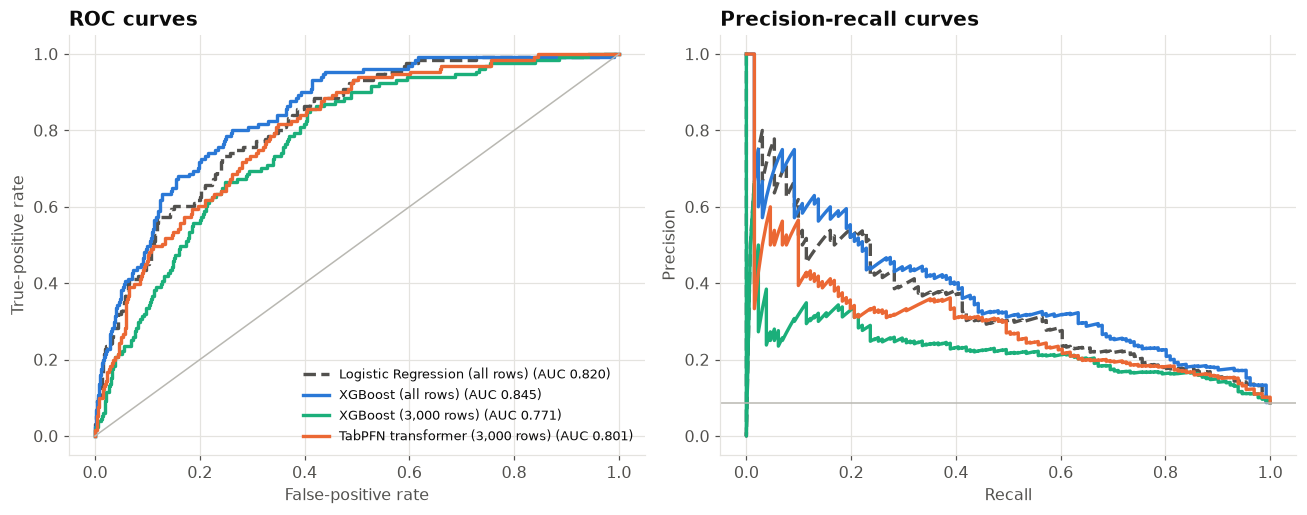

In [35]:
from sklearn.metrics import roc_curve, precision_recall_curve
styles = {k: (c, ls) for k, c, ls in zip(P.keys(), [vs.INK_2, vs.BLUE, vs.AQUA, vs.ORANGE], ["--", "-", "-", "-"])}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, p in P.items():
    c, ls = styles[name]
    f, t, _ = roc_curve(ys, p); axes[0].plot(f, t, color=c, ls=ls, lw=2.2, label=f"{name} (AUC {modeling.roc_auc_score(ys, p):.3f})")
    pr_, rc_, _ = precision_recall_curve(ys, p); axes[1].plot(rc_, pr_, color=c, ls=ls, lw=2.2, label=name)
axes[0].plot([0, 1], [0, 1], color="#b9b8b2", lw=1); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
axes[0].set_title("ROC curves"); axes[0].legend(fontsize=8.5, loc="lower right")
axes[1].axhline(ys.mean(), color="#b9b8b2", lw=1); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curves")
fig.tight_layout(); vs.savefig(fig, "10_roc_pr"); plt.show()

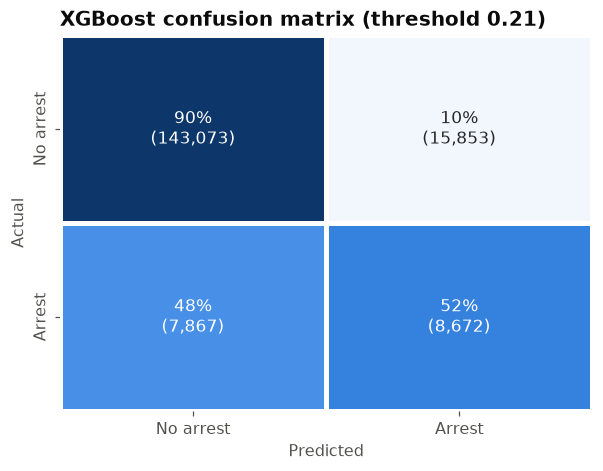

At this threshold the model finds **52%** of the arrests, and **35%** of the cases it flags really end in arrest (vs 9% by chance – about **3.8× better than random**).

In [36]:
# Confusion matrix of the best full-data model (XGBoost) on the full test set
from sklearn.metrics import confusion_matrix
pred = (p_xgb >= thr_xgb).astype(int)
cm = confusion_matrix(y_te, pred)
cmn = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.6, 4.4))
sns.heatmap(cmn, annot=[[f"{cmn[i, j]:.0f}%\n({cm[i, j]:,})" for j in range(2)] for i in range(2)], fmt="", cmap=vs.SEQ_BLUE, cbar=False,
            xticklabels=["No arrest", "Arrest"], yticklabels=["No arrest", "Arrest"], linewidths=2, linecolor="white", ax=ax, annot_kws={"size": 11})
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"XGBoost confusion matrix (threshold {thr_xgb:.2f})"); ax.grid(False)
fig.tight_layout(); vs.savefig(fig, "10_confusion"); plt.show()
tn, fp, fn_, tp = cm.ravel()
md_(f"At this threshold the model finds **{tp / (tp + fn_):.0%}** of the arrests, and **{tp / (tp + fp):.0%}** of the cases it flags really end in arrest "
    f"(vs {y_te.mean():.0%} by chance – about **{tp / (tp + fp) / y_te.mean():.1f}× better than random**).")
KEY["xgb_confusion"] = {"tn": int(tn), "fp": int(fp), "fn": int(fn_), "tp": int(tp), "threshold": float(thr_xgb)}

---
## 11 · Interpretation – what drives the prediction?

XGBoost can return an exact **additive contribution of every feature to every prediction** (SHAP values via `pred_contribs`). Positive = pushes the case toward arrest.

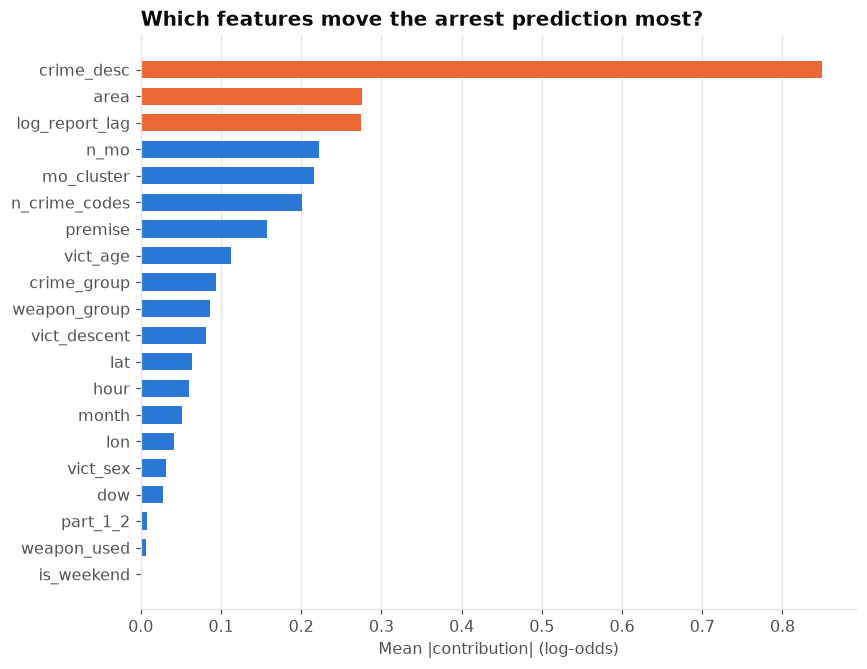

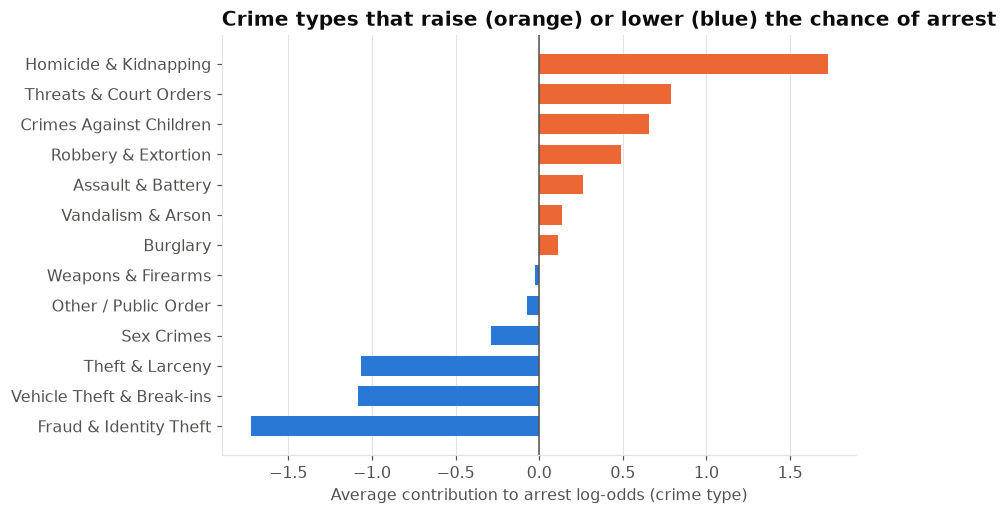

In [37]:
import xgboost as xgb_lib
n_exp = 20_000
Xe = X_te.iloc[:n_exp]
contrib = xgb.get_booster().predict(xgb_lib.DMatrix(Xe, enable_categorical=True), pred_contribs=True)
imp = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=modeling.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(imp.index, imp.values, color=[vs.ORANGE if i >= len(imp) - 3 else vs.BLUE for i in range(len(imp))], height=0.65)
ax.set_title("Which features move the arrest prediction most?"); ax.set_xlabel("Mean |contribution| (log-odds)"); ax.grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "11_feature_importance"); plt.show()
KEY["top_features"] = imp.sort_values(ascending=False).head(8).round(3).to_dict()

gi, di = modeling.FEATURES.index("crime_group"), modeling.FEATURES.index("crime_desc")
# the detailed description carries most of the crime-type signal, so add both contributions
cg_effect = pd.Series(contrib[:, gi] + contrib[:, di]).groupby(Xe["crime_group"].astype(str).to_numpy()).mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(cg_effect.index, cg_effect.values, color=[vs.ORANGE if v > 0 else vs.BLUE for v in cg_effect.values], height=0.65)
ax.axvline(0, color=vs.INK_2, lw=1); ax.set_xlabel("Average contribution to arrest log-odds (crime type)")
ax.set_title("Crime types that raise (orange) or lower (blue) the chance of arrest"); ax.grid(axis="y", visible=False)
fig.tight_layout(); vs.savefig(fig, "11_crime_group_effect"); plt.show()

---
## 12 · Communication – insights, recommendations and limitations

In [38]:
summary_path = TABLES / "key_results.json"
summary_path.write_text(json.dumps(KEY, indent=2, default=str))
print("Saved key results ->", summary_path.relative_to(ROOT))

Saved key results -> outputs\tables\key_results.json


**Reading the chart.** The detailed crime description is by far the strongest driver. Its neighbours are the **LAPD area** and the **reporting delay** (orange), then the number of MO codes and the **MO cluster** found in stage 8, which contribute as much as the victim details. Weapon type adds little *on top of* the crime description because descriptions such as "assault with deadly weapon" already encode it. Time of day and weekday barely matter.

In [39]:
prec = KEY["xgb_confusion"]["tp"] / (KEY["xgb_confusion"]["tp"] + KEY["xgb_confusion"]["fp"])
rec = KEY["xgb_confusion"]["tp"] / (KEY["xgb_confusion"]["tp"] + KEY["xgb_confusion"]["fn"])
tab = [r for r in KEY["small_test"] if "TabPFN" in r["Model"]]
small_x = [r for r in KEY["small_test"] if r["Model"].startswith("XGBoost (") and "all rows" not in r["Model"]][0]
big_x = [r for r in KEY["small_test"] if r["Model"] == "XGBoost (all rows)"][0]
ag = KEY["arrest_by_group"]
md_(f"""### Key insights
1. **Arrests are rare and very uneven.** Only **{KEY['arrest_rate']:.1%}** of reports end in an arrest: from **{ag['Homicide & Kidnapping']:.0f}%** (homicide & kidnapping) and **{ag['Crimes Against Children']:.0f}%** (crimes against children) down to **{ag['Vehicle Theft & Break-ins']:.1f}%** for vehicle crime and **{ag['Fraud & Identity Theft']:.1f}%** for fraud - the two groups that make up a large share of all reports.
2. **What happened matters more than where or when.** Crime type and weapon have the largest effects; area, time of day, weekday and victim sex or age have negligible-to-small ones.
3. **Speed matters.** Cases that end in an arrest are reported sooner (median 0 vs 1 day); the model also ranks reporting delay among its top drivers.
4. **MO codes carry real information.** The {KEY['mo_k']} MO clusters separate arrest rates from {min(r['arrest_rate_%'] for r in KEY['mo_profiles']):.1f}% to {max(r['arrest_rate_%'] for r in KEY['mo_profiles']):.1f}%, even between clusters that are all "assault".
5. **Crime volume is rising, with no weekend effect.** Reports grew steadily from 2020 to 2023 (Kendall tau about 0.5) and weekends are no busier than weekdays.
6. **Prediction works moderately well.** XGBoost reaches ROC-AUC **{KEY['full_test'][1]['ROC-AUC']:.2f}** (Logistic Regression {KEY['full_test'][0]['ROC-AUC']:.2f}). At the chosen threshold it finds **{rec:.0%}** of arrests and **{prec:.0%}** of its flags are correct, about **{prec / KEY['arrest_rate']:.1f}x** better than chance.
7. **Transformer vs trees.** With the same 3,000 training rows TabPFN scores ROC-AUC **{tab[0]['ROC-AUC']:.3f}** vs **{small_x['ROC-AUC']:.3f}** for XGBoost, and a higher precision at the top 9% ({tab[0]['Precision @top 9%']:.0%} vs {small_x['Precision @top 9%']:.0%}). The confidence intervals overlap because the test sample is small, so this is *suggestive*. XGBoost trained on all rows is still best ({big_x['ROC-AUC']:.3f}): **more data beat a cleverer model.**""")

### Key insights
1. **Arrests are rare and very uneven.** Only **9.4%** of reports end in an arrest: from **44%** (homicide & kidnapping) and **26%** (crimes against children) down to **2.7%** for vehicle crime and **1.8%** for fraud - the two groups that make up a large share of all reports.
2. **What happened matters more than where or when.** Crime type and weapon have the largest effects; area, time of day, weekday and victim sex or age have negligible-to-small ones.
3. **Speed matters.** Cases that end in an arrest are reported sooner (median 0 vs 1 day); the model also ranks reporting delay among its top drivers.
4. **MO codes carry real information.** The 9 MO clusters separate arrest rates from 0.7% to 20.3%, even between clusters that are all "assault".
5. **Crime volume is rising, with no weekend effect.** Reports grew steadily from 2020 to 2023 (Kendall tau about 0.5) and weekends are no busier than weekdays.
6. **Prediction works moderately well.** XGBoost reaches ROC-AUC **0.84** (Logistic Regression 0.81). At the chosen threshold it finds **52%** of arrests and **35%** of its flags are correct, about **3.7x** better than chance.
7. **Transformer vs trees.** With the same 3,000 training rows TabPFN scores ROC-AUC **0.801** vs **0.771** for XGBoost, and a higher precision at the top 9% (36% vs 26%). The confidence intervals overlap because the test sample is small, so this is *suggestive*. XGBoost trained on all rows is still best (0.845): **more data beat a cleverer model.**

### Recommendations
| # | Recommendation | Evidence |
|---|---|---|
| 1 | Treat **vehicle break-ins, theft and identity fraud** mainly as *prevention* problems (lighting, secure parking, anti-theft campaigns, bank cooperation) | Largest groups by volume but lowest arrest rates (stage 6, MO-fraud cluster 0.7 %) |
| 2 | **Promote immediate reporting** (online / phone / app) | Arrested cases are reported faster (stage 7) |
| 3 | Use the model only as a **workload-triage aid** for investigators, with human review and regular audits | Precision at the top 9 % is far above chance, but 1 in 2 arrests is still missed (stage 10) |
| 4 | **Improve data capture**: real times instead of 12:00, victim details, MO code descriptions, and publish 2024 once complete | Noon spike, 27 % unknown age, incomplete 2024 (stage 3) |

### Limitations and ethics
* **Transcribed data** - errors are possible; 2024 had to be excluded because cases were still open.
* **Association, not causation** - an arrest depends on whether a suspect can be found and on police practice, not only on the crime.
* **Victim descent is not suspect descent**, and area effects must never be turned into profiling of neighbourhoods. The model is an analytics exercise, **not a tool for decisions about individuals**.
* Only ~3,000 rows were given to TabPFN (CPU limit) and the transformer test sample is small, so its confidence intervals are wide.
* **Next steps:** add the official MO-code descriptions, use a time-based train/test split, model by reporting district, and run a fairness audit before any real-world use.